Saved plots/Zeeman_splittings_signed.png


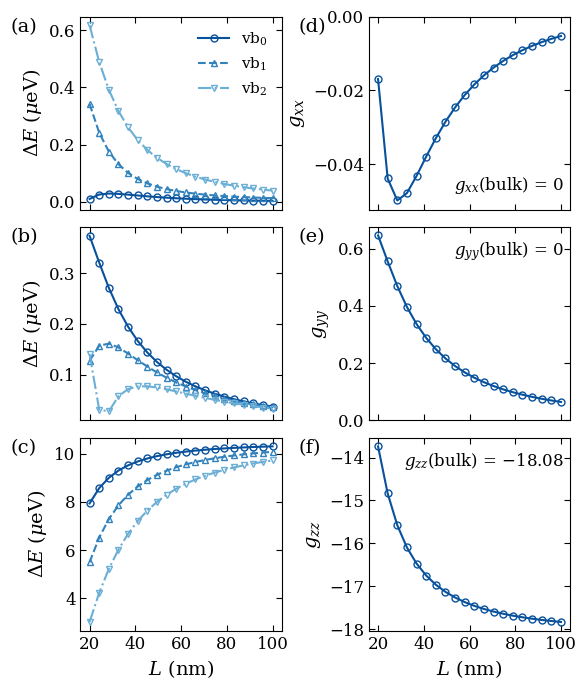

In [1]:
"""
Zeeman splittings of vb0, vb1, vb2 (left) and signed g factors of vb0 (right)
vs cross-section size L, for B || x, y, z.

Input: g{xx,yy,zz}_signed_vs_L_N100*.dat from gfactor_B{x,y,z}_signed_vs_L.py
columns: L(nm) g g_orb g_spin perp g_splitting E_vb0 gap_next split_vb0 split_vb1 split_vb2
Signs: spin-referenced, electron picture (g_ii > 0 <=> upper Zeeman state has larger <S_i>).
"""
import numpy as np
import matplotlib.pyplot as plt

FILES = {"xx": "output_data/gxx_signed_vs_L_N100.dat",
         "yy": "output_data/gyy_signed_vs_L_N100.dat",
         "zz": "output_data/gzz_signed_vs_L_N100.dat"}
BULK = {"xx": 0.0, "yy": 0.0, "zz": -18.08}   # sign of g_zz(bulk) in the same convention
BF = 0.01                                     # T, field used for the splittings
L_MIN = 20.0                                  # nm, rows with L < L_MIN are dropped from the data
SHOW_COMPONENTS = False                       # also draw orbital / spin parts of g
OUT = "plots/Zeeman_splittings_signed.png"

plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.8,
    "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 4, "ytick.major.size": 4,
    "xtick.minor.size": 2, "ytick.minor.size": 2,
})
C = ["#08519c", "#3182bd", "#6baed6"]
VB_STYLE = [dict(color=C[0], ls="-",  marker="o", label=r"vb$_0$"),
            dict(color=C[1], ls="--", marker="^", label=r"vb$_1$"),
            dict(color=C[2], ls="-.", marker="v", label=r"vb$_2$")]

fig, axs = plt.subplots(3, 2, figsize=(6, 7), sharex=True)
labels = iter("abcdef")
left_labels = [next(labels) for _ in range(3)]
right_labels = [next(labels) for _ in range(3)]

for row, comp in enumerate(["xx", "yy", "zz"]):
    d = np.loadtxt(FILES[comp])
    d = d[d[:, 0] >= L_MIN - 1e-9]            # drop L < L_MIN, then plot everything that is left
    L, g, g_orb, g_spin = d[:, 0], d[:, 1], d[:, 2], d[:, 3]
    splits = d[:, 8:11] * 1e6                 # eV -> ueV

    # ---- left: splittings of vb0, vb1, vb2 ----
    ax = axs[row, 0]
    for k in range(3):
        ax.plot(L, splits[:, k], ms=5, mfc="none", mew=1.0, lw=1.5, **VB_STYLE[k])
    ax.set_ylabel(r"$\Delta E$ ($\mu$eV)")
    ax.text(-0.35, 0.92, f"({left_labels[row]})", transform=ax.transAxes, fontsize=14)
    if row == 0:
        ax.legend(frameon=False, loc="upper right")

    # ---- right: signed g of vb0 ----
    ax = axs[row, 1]
    if SHOW_COMPONENTS:
        ax.plot(L, g_orb, "--", color=C[1], lw=1.2, label="orbital")
        ax.plot(L, g_spin, ":", color=C[2], lw=1.6, label="spin")
    ax.plot(L, g, "-o", color=C[0], ms=5, mfc="none", mew=1.0, lw=1.5,
            label=rf"$g_{{{comp}}}$" if SHOW_COMPONENTS else None)
    if np.any(g > 0) and np.any(g < 0):
        ax.axhline(0, color="k", lw=0.7)
        i = np.where(np.diff(np.sign(g)) != 0)[0][0]
        L0 = L[i] - g[i] * (L[i + 1] - L[i]) / (g[i + 1] - g[i])
        ax.axvline(L0, color="gray", lw=0.8, ls="--")
    ax.set_ylabel(rf"$g_{{{comp}}}$")
    ytxt, vtxt = (0.07, "bottom") if row == 0 else (0.93, "top")   # panel (d): label at bottom right
    ax.text(0.97, ytxt, rf"$g_{{{comp}}}$(bulk) = ${BULK[comp]:g}$", transform=ax.transAxes,
            ha="right", va=vtxt, fontsize=12)
    ax.text(-0.35, 0.92, f"({right_labels[row]})", transform=ax.transAxes, fontsize=14)
    if SHOW_COMPONENTS:
        ax.legend(frameon=False, loc="center right")

for ax in axs[-1]:
    ax.set_xlabel(r"$L$ (nm)")
    ax.set_xticks([20, 40, 60, 80, 100])

ax = axs[0, 1]                 # panel (d): y max = 0, with a zero line
ax.axhline(0, color="k", lw=0.7)
ax.set_ylim(top=0)
axs[1, 1].set_ylim(bottom=0)   # panel (e): y-axis starts at 0
fig.tight_layout(h_pad=0.4, w_pad=0.5)
fig.savefig(OUT, dpi=300)
print(f"Saved {OUT}")

Saved plots/Zeeman_splittings_signed.svg


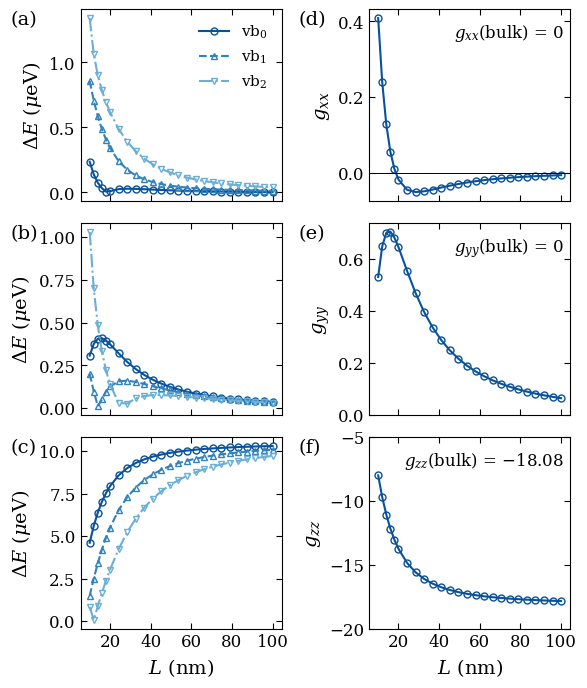

In [2]:
"""
Zeeman splittings of vb0, vb1, vb2 (left) and signed g factors of vb0 (right)
vs cross-section size L, for B || x, y, z.

Input: g{xx,yy,zz}_signed_vs_L_N100*.dat from gfactor_B{x,y,z}_signed_vs_L.py
columns: L(nm) g g_orb g_spin perp g_splitting E_vb0 gap_next split_vb0 split_vb1 split_vb2
Signs: spin-referenced, electron picture (g_ii > 0 <=> upper Zeeman state has larger <S_i>).
"""
import numpy as np
import matplotlib.pyplot as plt

FILES = {"xx": "output_data/gxx_signed_vs_L_N100.dat",
         "yy": "output_data/gyy_signed_vs_L_N100.dat",
         "zz": "output_data/gzz_signed_vs_L_N100.dat"}
BULK = {"xx": 0.0, "yy": 0.0, "zz": -18.08}   # sign of g_zz(bulk) in the same convention
BF = 0.01                                     # T, field used for the splittings
L_MIN = 0.0                                   # nm, no cut: plot the whole L range
SHOW_COMPONENTS = False                       # also draw orbital / spin parts of g
OUT = "plots/Zeeman_splittings_signed.svg"

plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.8,
    "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 4, "ytick.major.size": 4,
    "xtick.minor.size": 2, "ytick.minor.size": 2,
})
C = ["#08519c", "#3182bd", "#6baed6"]
VB_STYLE = [dict(color=C[0], ls="-",  marker="o", label=r"vb$_0$"),
            dict(color=C[1], ls="--", marker="^", label=r"vb$_1$"),
            dict(color=C[2], ls="-.", marker="v", label=r"vb$_2$")]

fig, axs = plt.subplots(3, 2, figsize=(6, 7), sharex=True)
labels = iter("abcdef")
left_labels = [next(labels) for _ in range(3)]
right_labels = [next(labels) for _ in range(3)]

for row, comp in enumerate(["xx", "yy", "zz"]):
    d = np.loadtxt(FILES[comp])
    d = d[d[:, 0] >= L_MIN - 1e-9]
    L, g, g_orb, g_spin = d[:, 0], d[:, 1], d[:, 2], d[:, 3]
    splits = d[:, 8:11] * 1e6                 # eV -> ueV

    # ---- left: splittings of vb0, vb1, vb2 ----
    ax = axs[row, 0]
    for k in range(3):
        ax.plot(L, splits[:, k], ms=5, mfc="none", mew=1.0, lw=1.5, **VB_STYLE[k])
    ax.set_ylabel(r"$\Delta E$ ($\mu$eV)")
    ax.text(-0.35, 0.92, f"({left_labels[row]})", transform=ax.transAxes, fontsize=14)
    if row == 0:
        ax.legend(frameon=False, loc="upper right")

    # ---- right: signed g of vb0 ----
    ax = axs[row, 1]
    if SHOW_COMPONENTS:
        ax.plot(L, g_orb, "--", color=C[1], lw=1.2, label="orbital")
        ax.plot(L, g_spin, ":", color=C[2], lw=1.6, label="spin")
    ax.plot(L, g, "-o", color=C[0], ms=5, mfc="none", mew=1.0, lw=1.5,
            label=rf"$g_{{{comp}}}$" if SHOW_COMPONENTS else None)
    if np.any(g > 0) and np.any(g < 0):
        ax.axhline(0, color="k", lw=0.7)
        i = np.where(np.diff(np.sign(g)) != 0)[0][0]
        L0 = L[i] - g[i] * (L[i + 1] - L[i]) / (g[i + 1] - g[i])
        if row != 0:                                # panel (d): no vertical line
            ax.axvline(L0, color="gray", lw=0.8, ls="--")
    ax.set_ylabel(rf"$g_{{{comp}}}$")
    ax.text(0.97, 0.93, rf"$g_{{{comp}}}$(bulk) = ${BULK[comp]:g}$", transform=ax.transAxes,
            ha="right", va="top", fontsize=12)
    ax.text(-0.35, 0.92, f"({right_labels[row]})", transform=ax.transAxes, fontsize=14)
    if SHOW_COMPONENTS:
        ax.legend(frameon=False, loc="center right")

for ax in axs[-1]:
    ax.set_xlabel(r"$L$ (nm)")
    ax.set_xticks([20, 40, 60, 80, 100])

axs[1, 1].set_ylim(bottom=0)   # panel (e): y-axis starts at 0
axs[2, 1].set_ylim(-20, -5)   # panel (f): y-axis limits
# axs[2, 1].axhline(-18.08, color="k", lw=0.9, ls=":")   # g_zz(bulk) = -18.08
fig.tight_layout(h_pad=0.4, w_pad=0.5)
fig.savefig(OUT, dpi=300)
print(f"Saved {OUT}")